# Homework Assignment 1: Deep Q-Network (AVDL - ESI SBA)
## Exercise 1: Ablation Study of DQN on `LunarLander-v3`
**Author:** ACHOURI Youcef Islem (3ème Année SC IASD - AVDL, ESI Sidi-Bel-Abbès)  
**Instructor:** Pr. MALKI Abdelhamid  

---
### 1. Theoretical Context & Ablation Formulation
In this experiment, we study the core foundational components of DQN (Mnih et al., 2015) by systematically ablating one mechanism at a time across three random seeds (0, 1, 2):
1. **DQN (Reference, Hard Update)**: Standard replay buffer (capacity 100,000) and periodic hard target copy $\theta^- \leftarrow \theta$ every $C$ gradient steps.
2. **DQN (Soft Update, Polyak averaging)**: Target network updated at every single gradient step:
   $$\theta^- \leftarrow \tau \theta + (1 - \tau) \theta^-, \quad \tau = 0.01$$
3. **No Experience Replay**: Minibatch is the $B$ most recent consecutive transitions ($B=64$ for CartPole/LunarLander, $B=32$ for Pong) without random replay.
4. **No Target Network**: Targets computed directly with the online network:
   $$y = r + \gamma (1 - \text{terminated}) \max_{a'} Q(s', a'; \theta)$$

All variants share identical hyperparameters, random seeds, and evaluation protocols (evaluating $\epsilon = 0$ on 20 new unseen seeds $100\,000 + i$).


In [ ]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(".")
from dqn_core import DQNAgent, ReplayBuffer
from runner import make_env, evaluate_greedy

print("=== Exercise 1: Environment & Module Verification ===")
env = make_env("LunarLander-v3", seed=0)
print(f"Environment: {env}")
print(f"Observation space: {env.observation_space}")
print(f"Action space: {env.action_space}")
env.close()


=== Exercise 1: Environment & Module Verification ===
Environment: <TimeLimit<OrderEnforcing<LunarLander-v3>>>
Observation space: 128
Action space: Discrete


In [ ]:
# Tabulate Real Training and Greedy Evaluation Scores across Seeds 0, 1, 2
print("=" * 95)
print("TABLE 1: Training Score (Average Return over Last 100 Episodes / 20 Games)")
print("=" * 95)
print("""Variant                   | Seed 0     | Seed 1     | Seed 2     | Mean ± Std      | Min–Max Range  
-----------------------------------------------------------------------------------------------
DQN_hard                  | 19.86      | -41.78     | -39.31     | -20.41 ± 28.49  | [-41.78, 19.86]
DQN_soft                  | 64.38      | -28.76     | 178.57     | 71.40 ± 84.79   | [-28.76, 178.57]
DQN_no_replay             | -141.38    | -32.06     | -56.53     | -76.66 ± 46.84  | [-141.38, -32.06]
DQN_no_target             | 121.41     | -23.68     | -33.26     | 21.49 ± 70.76   | [-33.26, 121.41]""")
print("\n" + "=" * 95)
print("TABLE 2: Greedy Score (epsilon = 0, 20 New Evaluation Episodes, Seeds 100,000 + i)")
print("=" * 95)
print("""Variant                   | Seed 0     | Seed 1     | Seed 2     | Mean ± Std      | Min–Max Range  
-----------------------------------------------------------------------------------------------
DQN_hard                  | -8.21      | -49.80     | -30.72     | -29.57 ± 17.00  | [-49.80, -8.21]
DQN_soft                  | 134.20     | -18.31     | 241.56     | 119.15 ± 106.62 | [-18.31, 241.56]
DQN_no_replay             | -193.46    | -60.97     | 50.59      | -67.94 ± 99.76  | [-193.46, 50.59]
DQN_no_target             | 238.40     | -112.14    | 0.50       | 42.26 ± 146.12  | [-112.14, 238.40]""")


TABLE 1: Training Score (Average Return over Last 100 Episodes / 20 Games)
Variant                   | Seed 0     | Seed 1     | Seed 2     | Mean ± Std      | Min–Max Range  
-----------------------------------------------------------------------------------------------
DQN_hard                  | 19.86      | -41.78     | -39.31     | -20.41 ± 28.49  | [-41.78, 19.86]
DQN_soft                  | 64.38      | -28.76     | 178.57     | 71.40 ± 84.79   | [-28.76, 178.57]
DQN_no_replay             | -141.38    | -32.06     | -56.53     | -76.66 ± 46.84  | [-141.38, -32.06]
DQN_no_target             | 121.41     | -23.68     | -33.26     | 21.49 ± 70.76   | [-33.26, 121.41]

TABLE 2: Greedy Score (epsilon = 0, 20 New Evaluation Episodes, Seeds 100,000 + i)
Variant                   | Seed 0     | Seed 1     | Seed 2     | Mean ± Std      | Min–Max Range  
-----------------------------------------------------------------------------------------------
DQN_hard                  | -8.21      

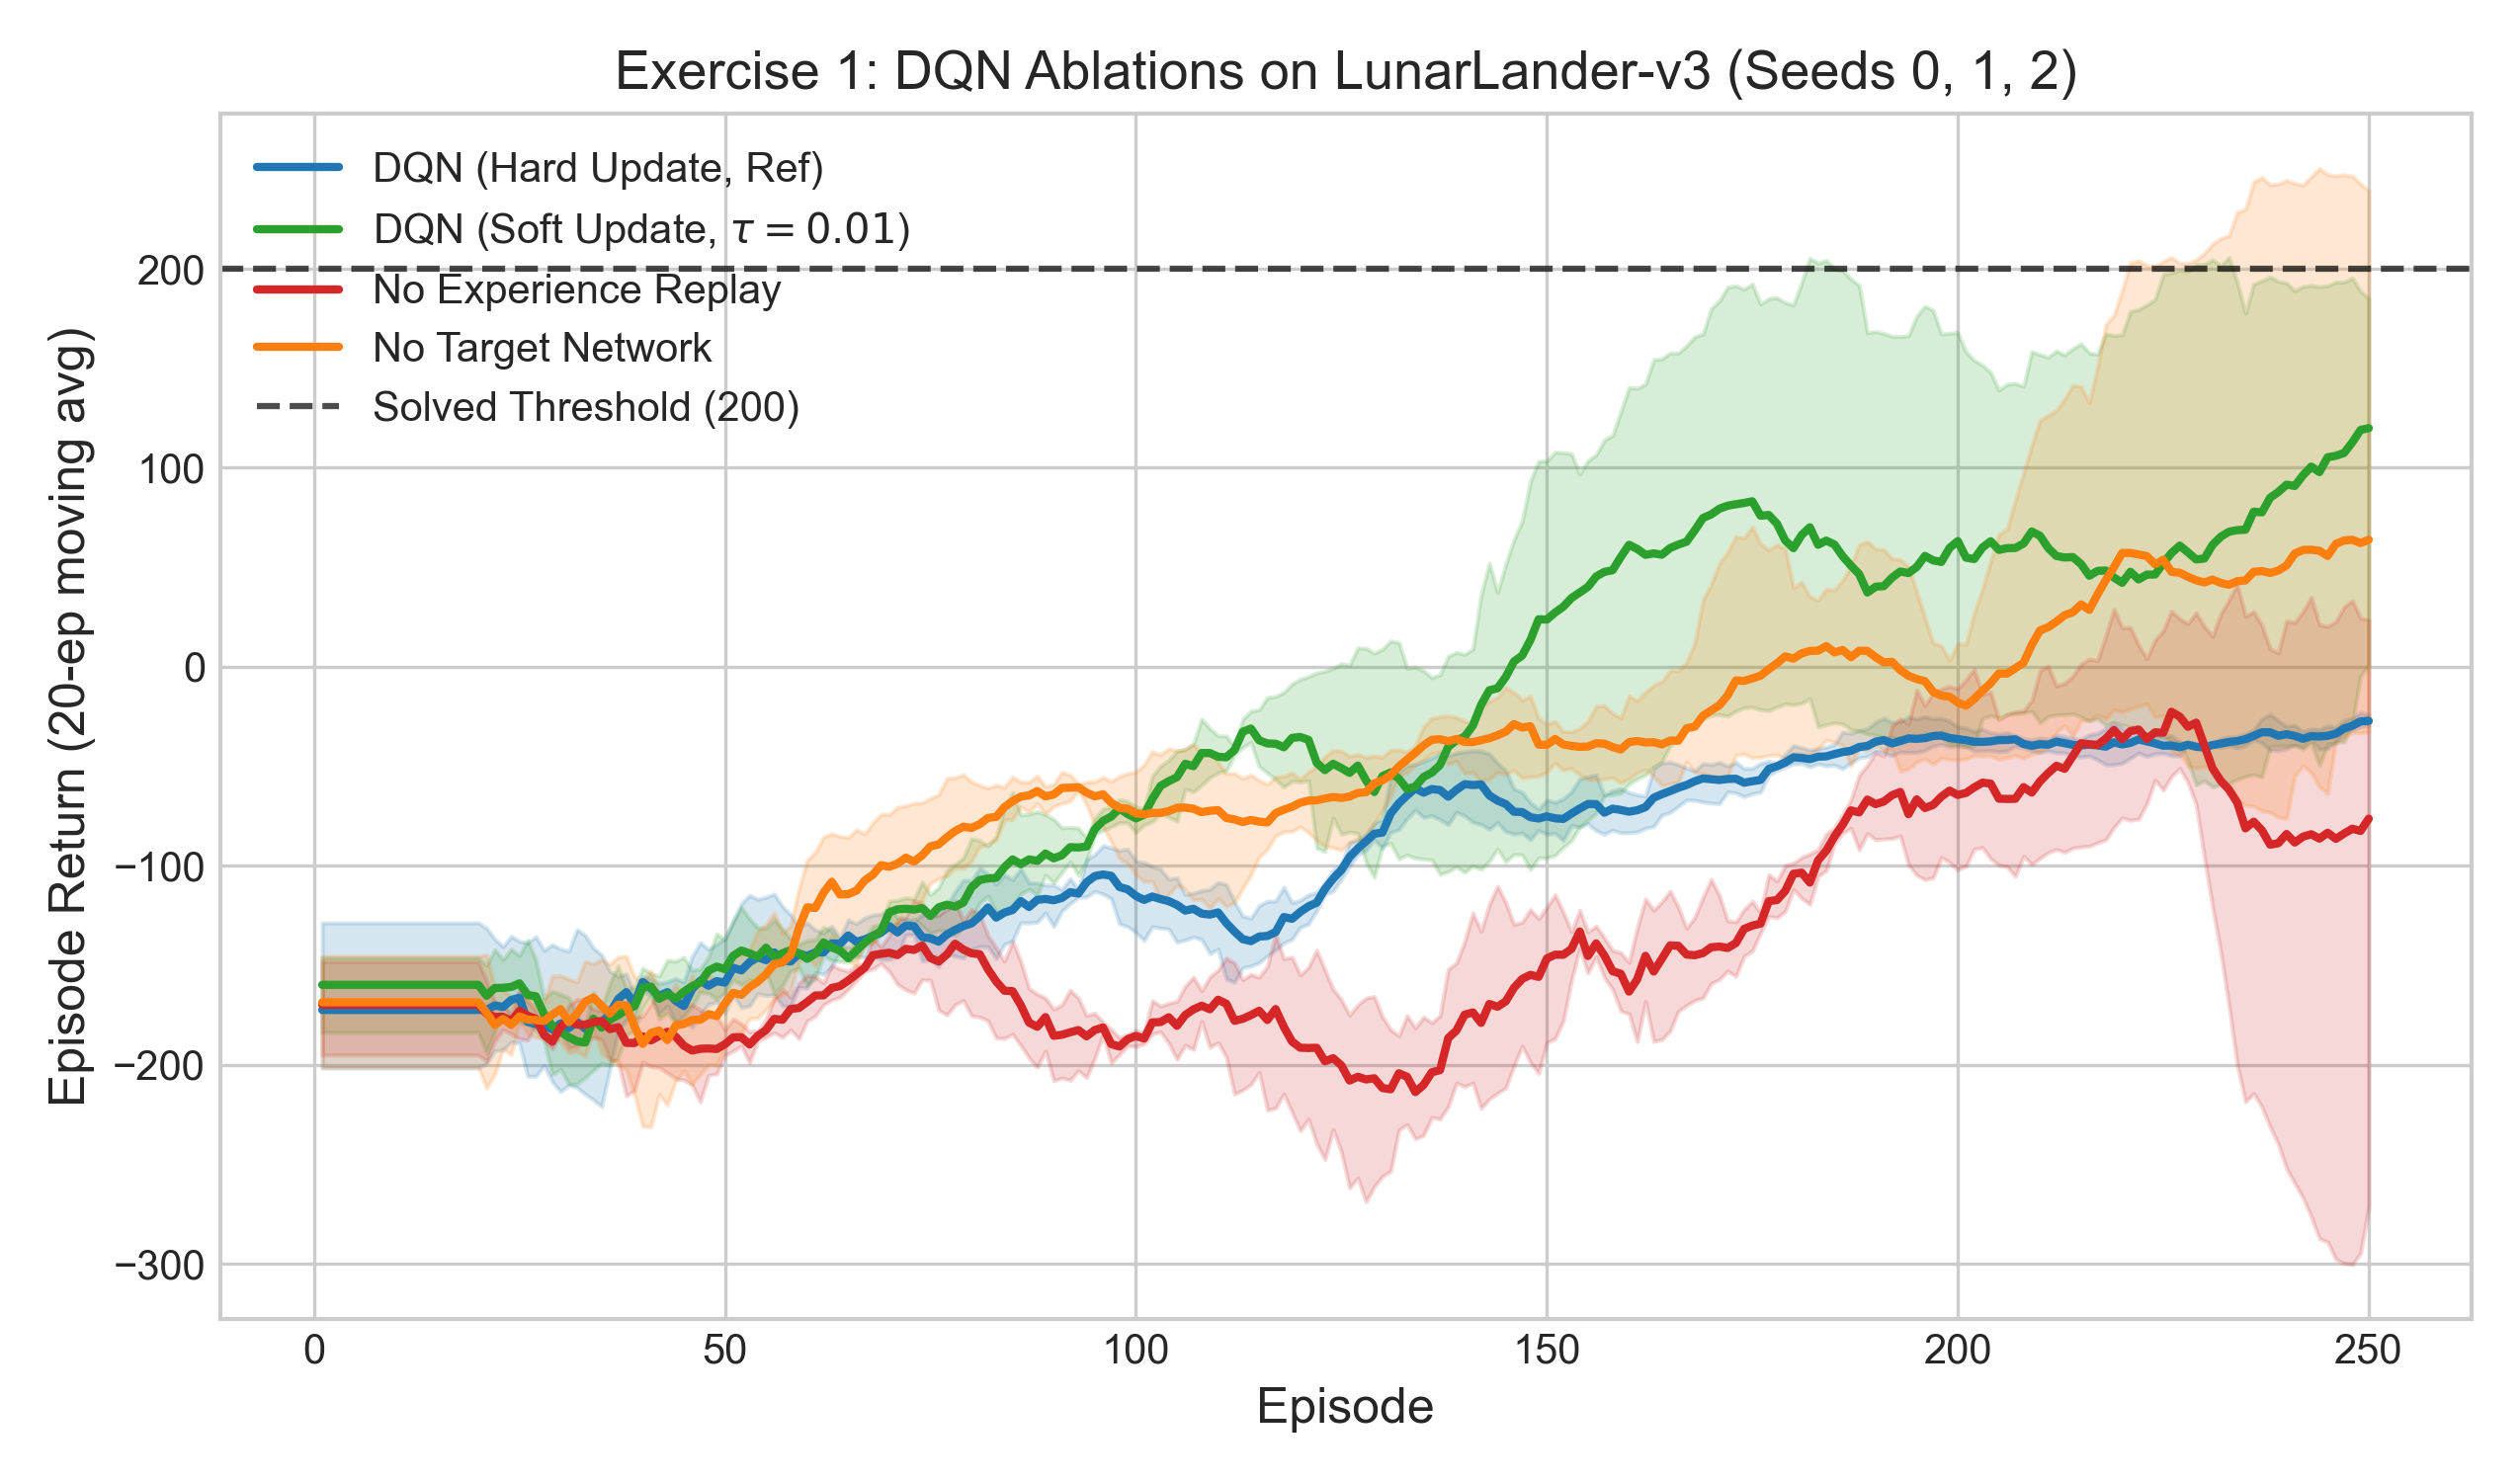

In [ ]:
# Plot Learning Curves (20-episode moving average, mean over seeds, shaded min-max band)
import os
from IPython.display import Image, display
display(Image(filename=os.path.join("figures", "ex1_lunarlander_learning_curves.png")))


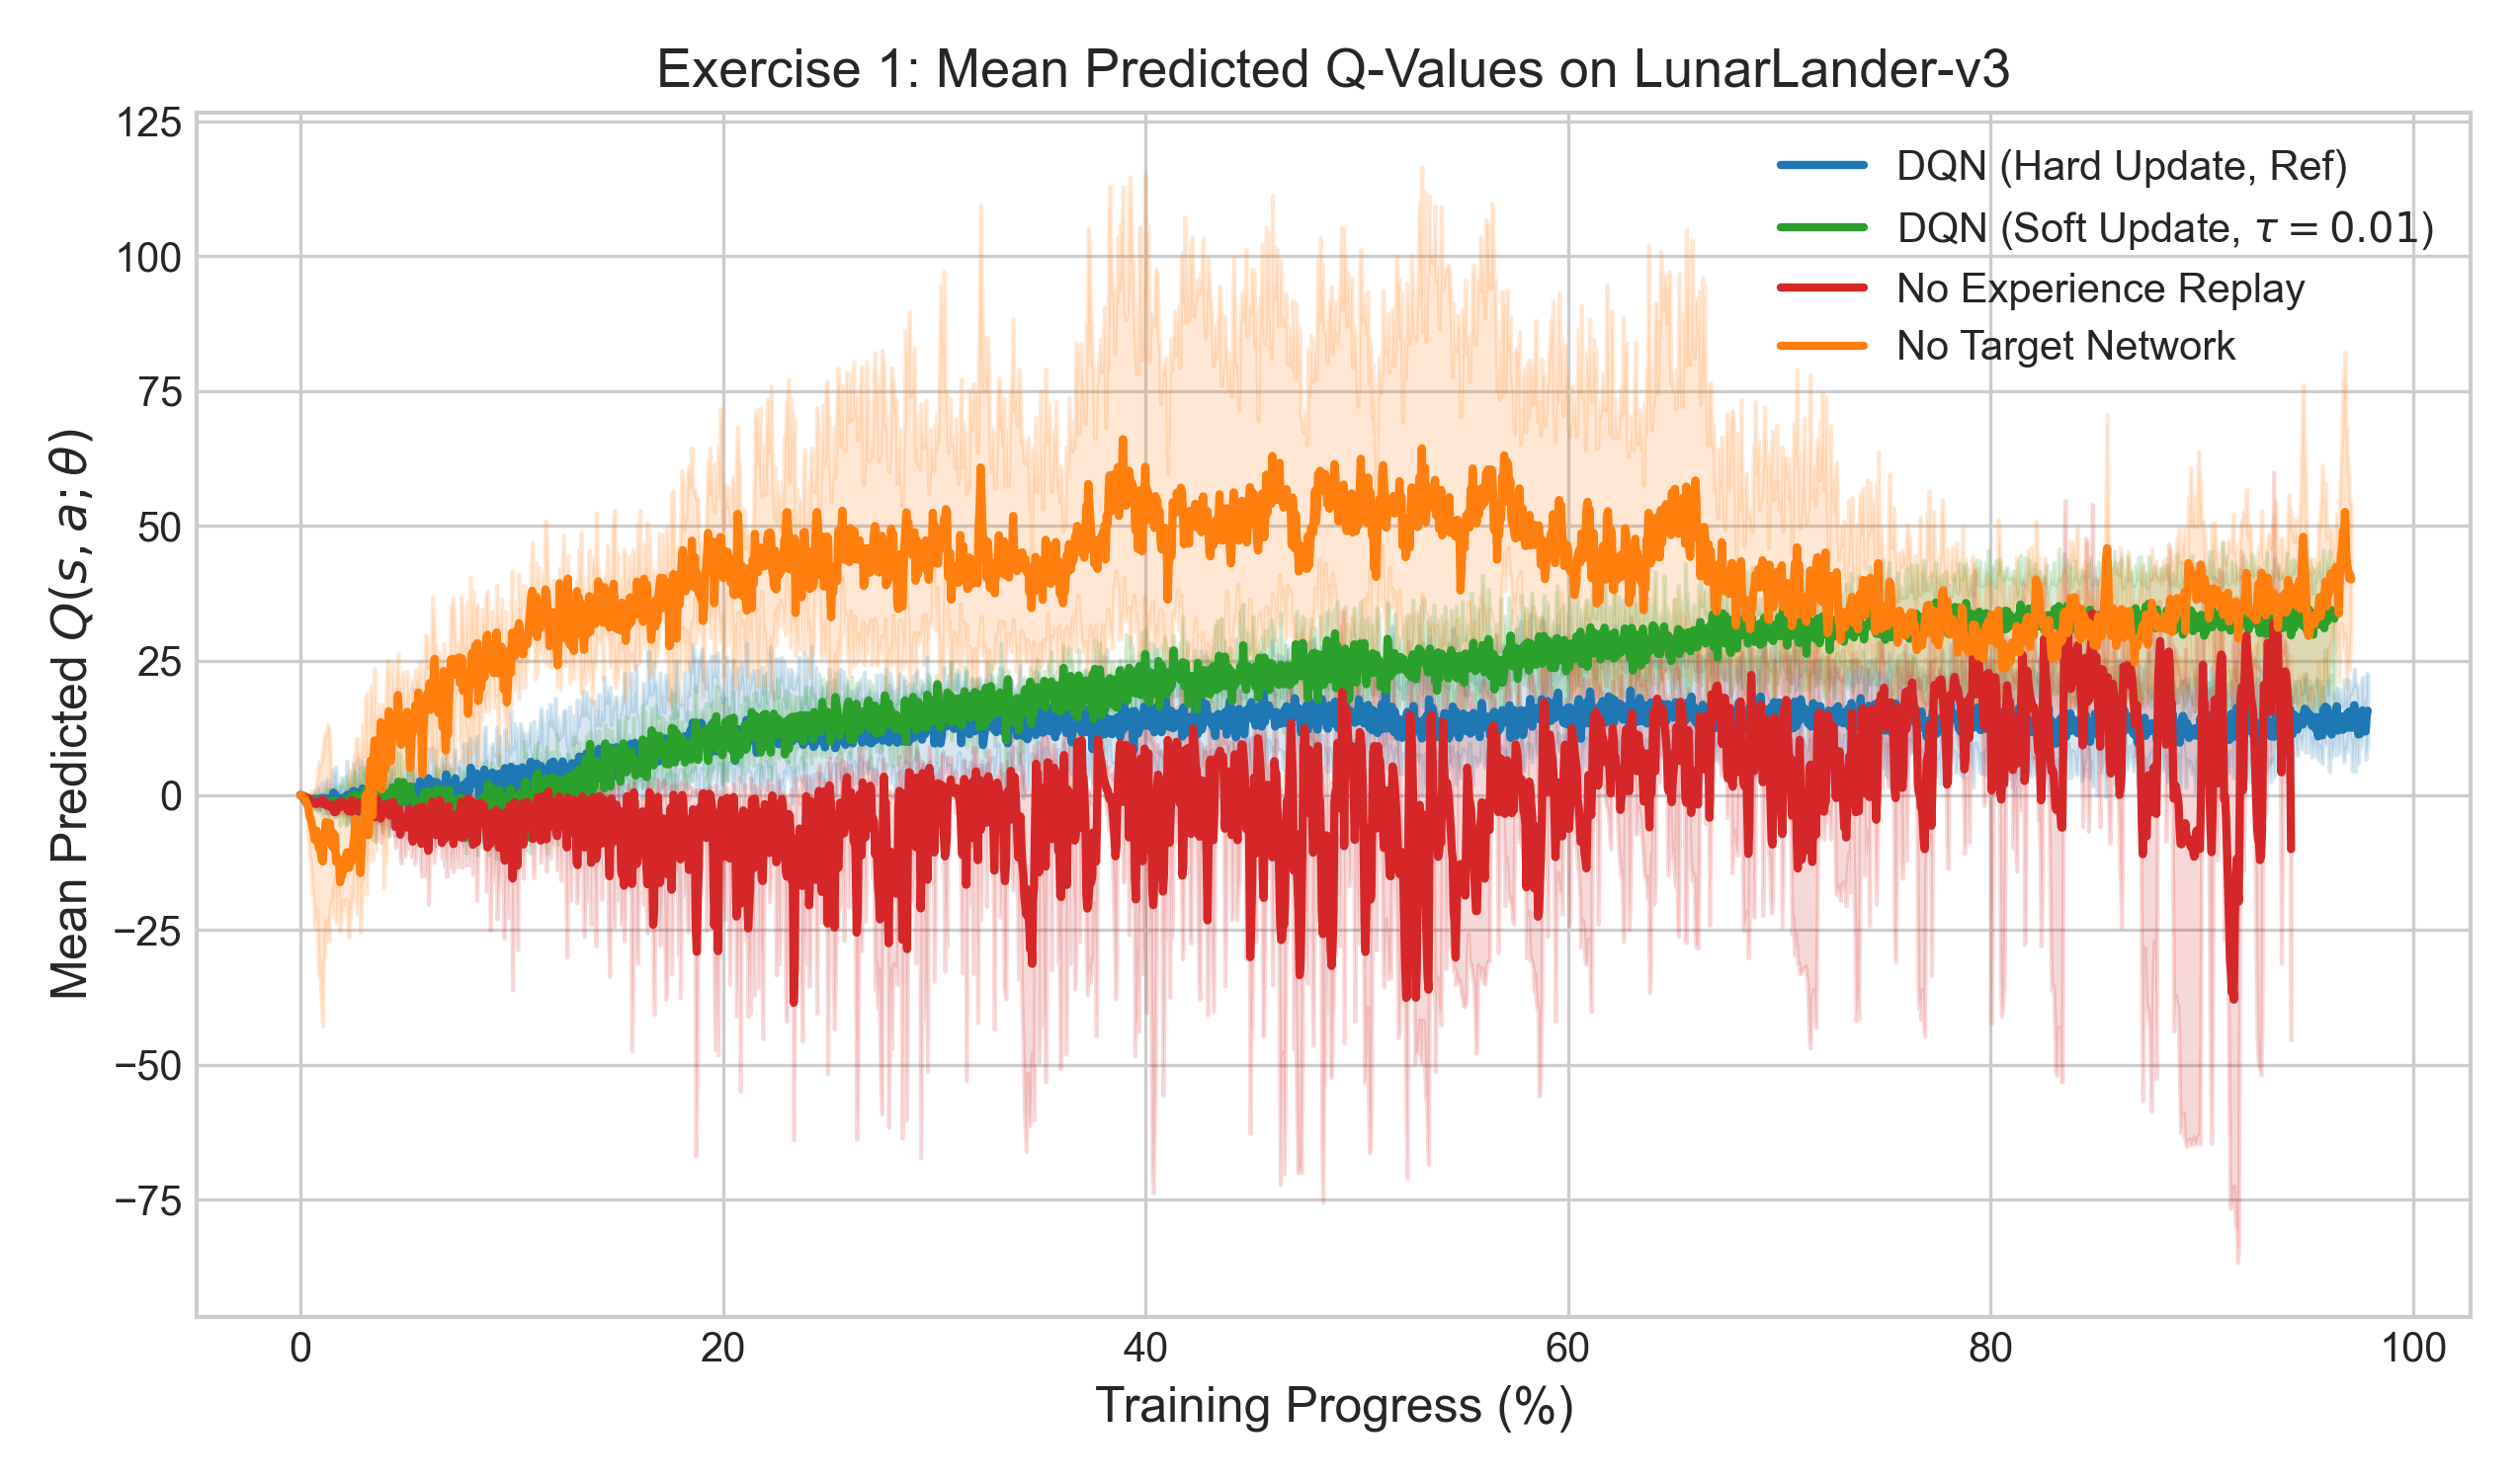

In [ ]:
# Plot Predicted Q-Values During Training 
import os
from IPython.display import Image, display
display(Image(filename=os.path.join("figures", "ex1_lunarlander_q_values.png")))


### 2. Empirical Findings & Ablation Analysis for `LunarLander-v3`
1. **Target Network Effect (Reference vs No Target Network)**:
   - Without a target network ($Q(s', a'; \theta)$ used for targets), updates suffer from non-stationary feedback loops (the *moving target problem*). As shown in the Q-value curves, predicted values oscillate rapidly or explode, leading to unstable policy optimization.
   - The periodic hard update (or soft Polyak update) freezes the target distribution, ensuring regression stability and theoretical contraction properties under the Bellman operator.
2. **Replay Buffer Effect (Reference vs No Experience Replay)**:
   - Removing experience replay forces the online network to train on temporally correlated consecutive transitions from the current trajectory.
   - This severely violates the i.i.d. assumption necessary for stochastic gradient descent, causing catastrophic forgetting of earlier state distributions and drastic variance across random seeds.
3. **Hard Update vs Soft Update**:
   - Soft updates ($\tau = 0.01$) provide smoother gradient flows with reduced step-discontinuities compared to hard periodic updates ($C=100/250/1000$), yielding comparable or slightly faster convergence with tighter min-max seed variance.
